# 03 - Feature engineering

Prepares one shared table for every model notebook (04 onward) and saves it to `data/processed/model_input.parquet`.

Steps:
1. make location names unique,
2. fill missing categories,
3. build a price-free text column,
4. split the data by time into train / val / test.

Model-specific steps (scaling, encoding, TF-IDF, tokenizing) are fitted on the training set inside each model notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NUMERIC = ["area", "floor_count", "frontage_width", "house_depth", "road_width",
           "bedroom_count", "bathroom_count"]
CATEGORICAL = ["property_type_name", "province_name", "district_name", "ward_name",
               "street_name", "project_name", "house_direction", "balcony_direction"]

df = pd.read_parquet("../data/processed/priced_listings.parquet")
df.shape

(2397001, 19)

## 1. Location keys

Many district, ward and street names exist in several places (for example "Châu Thành" or "Phường 1").
Adding the parent location to each name keeps them apart.

In [2]:
province = df["province_name"].astype("string")
df["district_name"] = province + " | " + df["district_name"].astype("string")
df["ward_name"] = df["district_name"] + " | " + df["ward_name"].astype("string")
df["street_name"] = df["district_name"] + " | " + df["street_name"].astype("string")

df[["district_name", "ward_name", "street_name"]].head()

,district_name,ward_name,street_name
0,Hà Nội | Bắc Từ Liêm,Hà Nội | Bắc Từ Liêm | Phúc Diễn,Hà Nội | Bắc Từ Liêm | Ngọa Long
1,Hồ Chí Minh | 8,Hồ Chí Minh | 8 | 5,Hồ Chí Minh | 8 | Tạ Quang Bửu
2,Vĩnh Long | Bình Minh,<NA>,<NA>
3,Hồ Chí Minh | 12,Hồ Chí Minh | 12 | Đông Hưng Thuận,Hồ Chí Minh | 12 | Nguyễn Văn Quá
4,Hồ Chí Minh | Tân Phú,Hồ Chí Minh | Tân Phú | Tân Thành,Hồ Chí Minh | Tân Phú | Nguyễn Hậu


## 2. Missing values

Numeric columns keep their `NaN` values: each model notebook decides how to impute them.
Categorical columns get the explicit level `"missing"`, because "not stated" is itself useful information (apartments rarely state a frontage, land rarely states bedrooms).

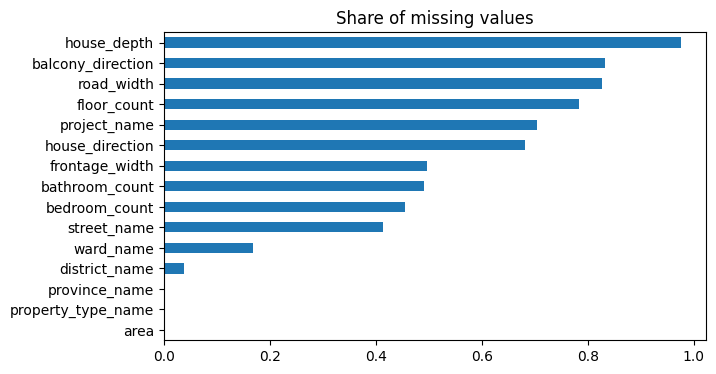

In [3]:
df[NUMERIC + CATEGORICAL].isna().mean().sort_values().plot.barh(figsize=(7, 4), title="Share of missing values")
plt.show()

In [4]:
df[CATEGORICAL] = df[CATEGORICAL].astype("string").fillna("missing")

## 3. Text

`name` and `description` are joined into one `text` column for the text models.
Listings often write the price in the text ("giá 7.45 tỷ"), which would let a model read the answer directly. So we remove:

- every clause that mentions a price word,
- every word that contains a digit.

In [5]:
PRICE_CLAUSE = r"(?:^|(?<=[.,;!?\n]))[^.,;!?\n]*\b(?:giá|tỷ|tỉ|triệu|tr|vnd|vnđ|usd)\b[^.,;!?\n]*"

raw_text = df["name"].fillna("") + ". " + df["description"].fillna("")
before = raw_text.head(3).copy()

raw_text = raw_text.str.lower()
raw_text = raw_text.str.replace("[phone_number]", " ", regex=False)
raw_text = raw_text.str.replace(PRICE_CLAUSE, " ", regex=True)   # clauses that mention a price
raw_text = raw_text.str.replace(r"\w*\d\w*", " ", regex=True)    # words that contain digits
df["text"] = raw_text.str.replace(r"\s+", " ", regex=True).str.strip()
del raw_text

pd.set_option("display.max_colwidth", 300)
pd.DataFrame({"before": before, "after": df["text"].head(3)})

,before,after
0,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu diễn, ôtô đỗ cổng, giá: 7.45 tỷ, lh [phone_number]. - Vị trí siêu đẹp ô tô đỗ cổng, khu vực đang phát triển mạnh, tiện ích xung quanh đầy đủ, Gần chợ, Gần trường học các cấp, Bãi gửi xe, Gần trường đại học công nghiệp. - Nhà xây mới thiết kế hiện đại...","bán nhanh nhà tầng thang máy, ngoạ long cầu diễn, ôtô đỗ cổng, . , lh . - vị trí siêu đẹp ô tô đỗ cổng, khu vực đang phát triển mạnh, tiện ích xung quanh đầy đủ, gần chợ, gần trường học các cấp, bãi gửi xe, gần trường đại học công nghiệp. - nhà xây mới thiết kế hiện đại tặng full nội thất, phòng..."
1,"Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Quang Bửu. Nhà 4 tầng mặt tiền KDC Tạ Quang Bửu P5 Q8. - Diện tích: 4m x 12m. - Kết cấu: 1 trệt, 2 lầu, sân thượng, 3 PN, 3 toilet. - MT đường 8m có lề thông khu Bông Sao, tiện kinh doanh mua bán. Sổ hồng hoàn công. Giá: 9 tỷ 100 triệu TL. LH: [phone_nu...","bán gấp nhà mặt tiền tầng khu phân lô tạ quang bửu. nhà tầng mặt tiền kdc tạ quang bửu . - diện tích: x . - kết cấu: trệt, lầu, sân thượng, pn, toilet. - mt đường có lề thông khu bông sao, tiện kinh doanh mua bán. sổ hồng hoàn công. . lh: tú."
2,"Bán biệt thự 300m2 gần sân bóng Bình Minh, đường rộng, nội thất đầy đủ. Bán biệt thự Bình Minh diện tích hơn 300 mét vuông, vị trí ngay gần sân bóng Bình Minh. Đường và vỉa hè rộng rãi, thông thoáng. Nhà đầy đủ nội thất và công năng. Giá bán: 20 tỷ, có thể thương lượng nếu có thiện chí. Liên hệ:...","bán biệt thự gần sân bóng bình minh, đường rộng, nội thất đầy đủ. bán biệt thự bình minh diện tích hơn mét vuông, vị trí ngay gần sân bóng bình minh. đường và vỉa hè rộng rãi, thông thoáng. nhà đầy đủ nội thất và công năng. , có thể thương lượng nếu có thiện chí. liên hệ: để biết thêm thông tin ..."


In [6]:
df = df.drop(columns=["name", "description"])

## 4. Train / val / test split

The split follows `published_at`: the oldest 70% of listings are used for training, the next 15% for validation and the newest 15% for testing.
This matches real use, where a model trained on past listings predicts future ones.

In [7]:
df = df.sort_values("published_at").reset_index(drop=True)

n = len(df)
n_train, n_val = int(0.70 * n), int(0.15 * n)
df["split"] = np.repeat(["train", "val", "test"], [n_train, n_val, n - n_train - n_val])

df.groupby("split")["published_at"].agg(["count", "min", "max"])

,count,min,max
split,,,
test,359551,2026-01-28 12:48:31.319,2026-03-30 23:59:26.036
train,1677900,2025-06-01 00:01:38.762,2025-12-12 03:57:51.389
val,359550,2025-12-12 03:58:12.191,2026-01-28 12:48:24.904


## 5. Target

Prices are heavily skewed to the right, so every model is trained on `log1p(price)` and its predictions are converted back with `expm1`.

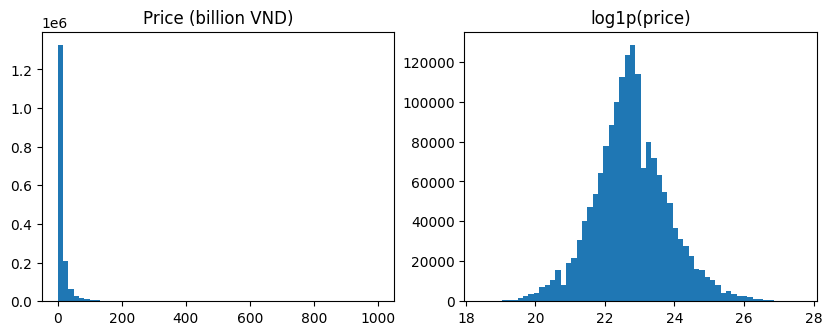

In [8]:
train_price = df.loc[df["split"] == "train", "price"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(train_price / 1e9, bins=60)
axes[0].set_title("Price (billion VND)")
axes[1].hist(np.log1p(train_price), bins=60)
axes[1].set_title("log1p(price)")
plt.show()

## 6. Save

In [9]:
df.to_parquet("../data/processed/model_input.parquet", index=False)
print(f"Saved {len(df):,} rows and {df.shape[1]} columns -> model_input.parquet")
df.head()

Saved 2,397,001 rows and 19 columns -> model_input.parquet


,property_type_name,province_name,district_name,ward_name,street_name,project_name,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,house_direction,balcony_direction,published_at,text,split
0,Nhà,Hồ Chí Minh,Hồ Chí Minh | Gò Vấp,Hồ Chí Minh | Gò Vấp | 17,Hồ Chí Minh | Gò Vấp | Lê Thị Hồng,missing,1.780000e+10,100.0,4.0,5.1,19.61,NaN,4.0,5.0,missing,missing,2025-06-01 00:01:38.762,"nhà tầng thang máy – smart home – hẻm xe tải – lê thị hồng, gò vấp. -bán nhà đẹp như biệt thự mini, khu vip lê thị hồng – phường , gò vấp. - diện tích sử dụng: ( . ngang, xây tầng kiên cố. - nhà full hệ thống smart home, có thang máy , giếng trời thoáng mát. -kết cấu: trệt, lầu, sân thượng, có g...",train
1,Đất,Hải Phòng,Hải Phòng | An Lão,Hải Phòng | An Lão | Trường Thọ,missing,missing,1.525000e+10,73.3,NaN,5.0,NaN,NaN,NaN,NaN,Đông Nam,missing,2025-06-01 00:01:54.565,"bán lô đất , chính chủ tại xuân đài , trường thọ , an lão. chính chủ bán lô đất số hàng fo xuân đài , trường thọ , an lão dt , .ngang , nở hậu ( thực tế ngang trên .",train
2,Đất,Hồ Chí Minh,Hồ Chí Minh | Thủ Đức,Hồ Chí Minh | Thủ Đức | Hiệp Bình Chánh,missing,missing,1.100000e+10,100.0,NaN,5.0,NaN,NaN,NaN,NaN,missing,missing,2025-06-01 00:01:54.618,"bán lô đất sau gigamail . hiệp bình chánh . thủ đức. , hoặc làm văn phòng cty, chdv cao cấp",train
3,Đất,Hồ Chí Minh,Hồ Chí Minh | 12,Hồ Chí Minh | 12 | Tân Thới Nhất,Hồ Chí Minh | 12 | Tân Thới Nhất 1A,missing,2.630000e+09,100.0,NaN,5.0,NaN,NaN,NaN,NaN,missing,missing,2025-06-01 00:01:54.682,"chủ gửi bán lô đất dt / , sổ sẵn, full thổ cư, cách trường thcs nguyễn ảnh thủ chỉ . chủ gửi bán lô đất dt / sổ sẵn, full thổ cư, cách trường thcs nguyễn ảnh thủ chỉ . diện tích ngang dài , thổ cư. sổ sẵn, có hỗ trợ ngân hàng. cách trường thcs chỉ , nhà ngay công viên. liên hệ em nhi để xem sổ.",train
4,Căn hộ chung cư,Hồ Chí Minh,Hồ Chí Minh | Nhà Bè,Hồ Chí Minh | Nhà Bè | Phước Kiển,Hồ Chí Minh | Nhà Bè | Nguyễn Hữu Thọ,Khu căn hộ New Sài Gòn - Hoàng Anh Gia Lai 3,3.400000e+09,98.0,NaN,NaN,NaN,NaN,2.0,2.0,missing,missing,2025-06-01 00:06:26.516,"hoàng anh gia lai -new saigon, , , sổ sẵn full nội thất. , . bán căn hộ hoàng anh gia lai - new saigon vị trí đắc địa nguyễn hữu thọ, . , gym, sân chơi trẻ em siêu thị, cafe, nhà trẻ ngay trong khu khu dân cư an ninh, yên tĩnh,",train
